# Day 9-11: Customer Churn Classification

This notebook follows the style with short explanations, runnable code, and results. It compares K-Nearest Neighbors, Gaussian Naive Bayes, a Decision Tree, a Random Forest, and Logistic Regression. The target is `churned` (1 = canceled, 0 = stayed); `customer_id` is excluded from predictors.

## 1. Load and inspect the data

Load the `Customer data` sheet, check its size and data quality, and inspect the target balance.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
paths=[Path('customer_churn_classification.xlsx'),Path('../customer_churn_classification.xlsx'),Path('Assignment Day-9-11/customer_churn_classification.xlsx')]
data_path=next((p for p in paths if p.exists()),None)
if data_path is None: raise FileNotFoundError('Run from this folder, its parent, or the Day-9-11 folder.')
df=pd.read_excel(data_path,sheet_name='Customer data')
print('Shape:',df.shape,'| missing values:',int(df.isna().sum().sum()),'| duplicate rows:',int(df.duplicated().sum()))
print('Target counts (0=stayed, 1=churned):')
print(df.churned.value_counts().sort_index().to_string())
print('\nPreview:')
print(df.head().to_string(index=False))

Shape: (500, 12) | missing values: 0 | duplicate rows: 0
Target counts (0=stayed, 1=churned):
churned
0    360
1    140

Preview:
customer_id  age_years  tenure_months  monthly_fee_inr  weekly_usage_hours  support_tickets_6m  late_payments_6m  discount_percent  auto_pay  satisfaction_score  competitor_offer  churned
      C0001         39             50              800                11.5                   3                 1                20         1                   9                 1        0
      C0002         58             20             1100                16.6                   0                 0                 0         0                   9                 1        0
      C0003         43              9             1350                14.6                   3                 0                 0         1                   7                 0        0
      C0004         42             40              850                13.5                   6                 1      

## 2. Prepare features and make an 80/20 stratified split

Remove `churned` and `customer_id` from X. Stratification keeps the churn proportions similar in both sets. The test set stays untouched during tuning.

In [2]:
X=df.drop(columns=['churned','customer_id'])
y=df['churned']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
split_counts=pd.DataFrame({'Stayed (0)':[(y_train==0).sum(),(y_test==0).sum()],'Churned (1)':[(y_train==1).sum(),(y_test==1).sum()]},index=['Train','Test'])
print(split_counts.to_string())
print('Features:',', '.join(X.columns))

       Stayed (0)  Churned (1)
Train         288          112
Test           72           28
Features: age_years, tenure_months, monthly_fee_inr, weekly_usage_hours, support_tickets_6m, late_payments_6m, discount_percent, auto_pay, satisfaction_score, competitor_offer


## 3. Tune KNN on training folds

KNN depends on distances, so standardize inside a pipeline. Compare candidate K values with 5-fold stratified cross-validation on training data only. Recall is used to prioritize catching churners for a retention campaign.

In [3]:
knn_pipeline=Pipeline([('scaler',StandardScaler()),('model',KNeighborsClassifier())])
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
k_values=[3,5,7,9,11,15,21,25]
knn_search=GridSearchCV(knn_pipeline,{'model__n_neighbors':k_values},scoring='recall',cv=cv,n_jobs=-1,return_train_score=True)
knn_search.fit(X_train,y_train)
knn_cv=pd.DataFrame({'K':knn_search.cv_results_['param_model__n_neighbors'].astype(int),'Mean CV recall':knn_search.cv_results_['mean_test_score']}).sort_values('K')
print('Selected K:',knn_search.best_params_['model__n_neighbors'])
print('Best mean CV recall:',round(knn_search.best_score_,3))
print(knn_cv.to_string(index=False))

Selected K: 3
Best mean CV recall: 0.501
 K  Mean CV recall
 3        0.500791
 5        0.466008
 7        0.430435
 9        0.358893
11        0.349407
15        0.303953
21        0.259289
25        0.241502


## 4. Fit and compare five classifiers

KNN and Logistic Regression use training-fitted scaling in pipelines. Compare accuracy, precision, recall, F1, false alarms, missed churners, and confusion matrices on the same test set. Confusion matrix order is `[[TN, FP], [FN, TP]]`.

In [4]:
models={
 'KNN (CV tuned)':knn_search.best_estimator_,
 'Gaussian Naive Bayes':GaussianNB(),
 'Decision Tree':DecisionTreeClassifier(random_state=42),
 'Random Forest':RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=-1),
 'Logistic Regression':Pipeline([('scaler',StandardScaler()),('model',LogisticRegression(max_iter=2000,random_state=42))]),
}
results=[]; predictions={}
for name,model in models.items():
 model.fit(X_train,y_train)
 pred=model.predict(X_test); predictions[name]=pred
 tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
 results.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision (churn)':precision_score(y_test,pred,zero_division=0),'Recall (churn)':recall_score(y_test,pred,zero_division=0),'F1 (churn)':f1_score(y_test,pred,zero_division=0),'False alarms (FP)':fp,'Missed churners (FN)':fn,'TN':tn,'TP':tp})
results_df=pd.DataFrame(results).set_index('Model').sort_values('Recall (churn)',ascending=False)
print(results_df.round(3).to_string())

                      Accuracy  Precision (churn)  Recall (churn)  F1 (churn)  False alarms (FP)  Missed churners (FN)  TN  TP
Model                                                                                                                         
Logistic Regression       0.82              0.656           0.750       0.700                 11                     7  61  21
Decision Tree             0.80              0.633           0.679       0.655                 11                     9  61  19
Random Forest             0.84              0.731           0.679       0.704                  7                     9  65  19
Gaussian Naive Bayes      0.78              0.600           0.643       0.621                 12                    10  60  18
KNN (CV tuned)            0.76              0.600           0.429       0.500                  8                    16  64  12


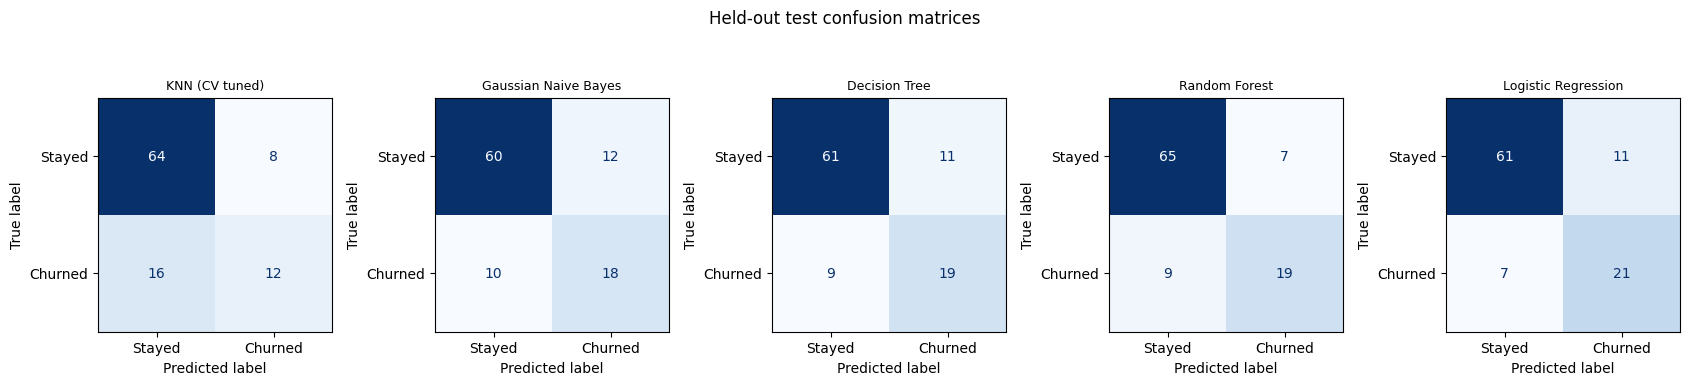

In [5]:
fig,axes=plt.subplots(1,len(models),figsize=(17,3.6))
for ax,(name,pred) in zip(axes,predictions.items()):
 ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],display_labels=['Stayed','Churned'],cmap='Blues',colorbar=False,ax=ax)
 ax.set_title(name,fontsize=9)
fig.suptitle('Held-out test confusion matrices',y=1.05)
fig.tight_layout()
plt.show()

## 5. Compare campaign trade-offs

Recall measures the share of actual churners caught. False positives are customers flagged for outreach who would have stayed. Precision measures how many flagged customers actually churned. The preferred model depends on the relative cost of a missed cancellation and an unnecessary contact.

In [6]:
most_recall=results_df['Recall (churn)'].idxmax()
fewest_fp=results_df['False alarms (FP)'].idxmin()
print('Highest churn recall:',most_recall,'=',round(results_df.loc[most_recall,'Recall (churn)'],3))
print('Fewest false alarms:',fewest_fp,'=',int(results_df.loc[fewest_fp,'False alarms (FP)']))

Highest churn recall: Logistic Regression = 0.75
Fewest false alarms: Random Forest = 7


## 6. Inspect what the models learned

A shallow tree is easier to display. Forest importance and logistic coefficients describe patterns learned from this sample; they do not show that a feature causes churn.

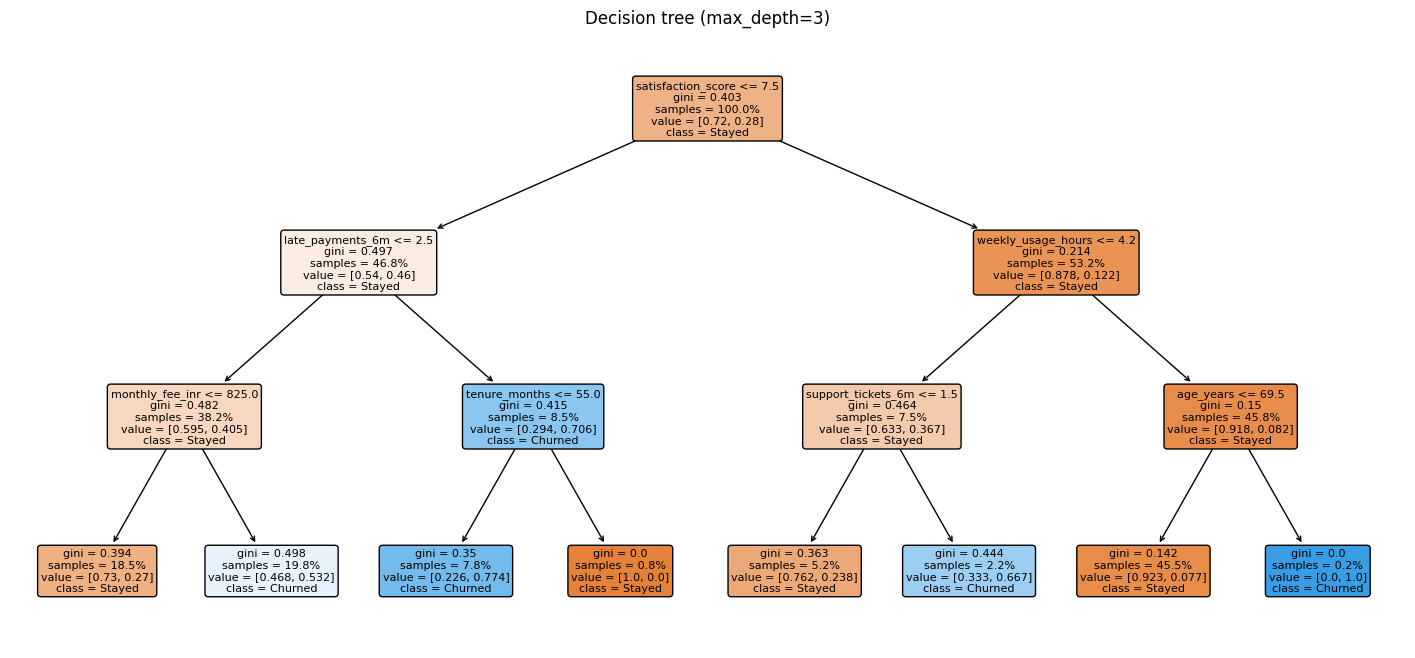

In [7]:
small_tree=DecisionTreeClassifier(max_depth=3,random_state=42).fit(X_train,y_train)
fig,ax=plt.subplots(figsize=(18,8))
plot_tree(small_tree,feature_names=X.columns,class_names=['Stayed','Churned'],filled=True,rounded=True,proportion=True,fontsize=8,ax=ax)
ax.set_title('Decision tree (max_depth=3)')
plt.show()

weekly_usage_hours    0.191204
satisfaction_score    0.161979
tenure_months         0.124353
monthly_fee_inr       0.113912
age_years             0.113346
support_tickets_6m    0.098326
late_payments_6m      0.085023
discount_percent      0.051636
competitor_offer      0.037608
auto_pay              0.022613


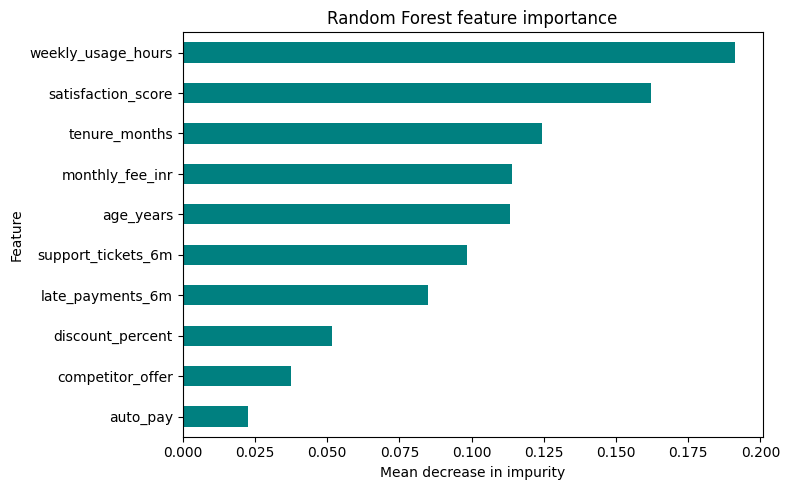

In [8]:
forest=models['Random Forest']
forest_importance=pd.Series(forest.feature_importances_,index=X.columns).sort_values()
ax=forest_importance.plot(kind='barh',figsize=(8,5),color='teal')
ax.set(title='Random Forest feature importance',xlabel='Mean decrease in impurity',ylabel='Feature')
plt.tight_layout()
plt.show()
print(forest_importance.sort_values(ascending=False).to_string())

In [9]:
logistic=models['Logistic Regression'].named_steps['model']
coefficients=pd.Series(logistic.coef_[0],index=X.columns).sort_values()
print('Intercept:',round(float(logistic.intercept_[0]),3))
print('Positive values raise the model churn log-odds; negative values lower them, holding the other standardized features fixed.')
print(coefficients.to_string())

Intercept: -1.464
Positive values raise the model churn log-odds; negative values lower them, holding the other standardized features fixed.
weekly_usage_hours   -0.779512
satisfaction_score   -0.522834
tenure_months        -0.518022
auto_pay             -0.333217
discount_percent     -0.039146
age_years             0.144534
monthly_fee_inr       0.546110
competitor_offer      0.665575
late_payments_6m      0.702986
support_tickets_6m    0.753621


## 7. Recommendation

On this split, Logistic Regression catches the most churners, while Random Forest has the fewest false alarms. I would start with Logistic Regression for a retention campaign when missing a likely cancellation is more costly than contacting some customers who would have stayed. Before deployment, validate on newer customer data, check probability calibration, and choose an outreach threshold based on campaign capacity and cost.